In [5]:
import numpy as np
import networkx as nx
from pympler import asizeof
import matplotlib.pyplot as plt


100.000144 MB
0.28028 MB


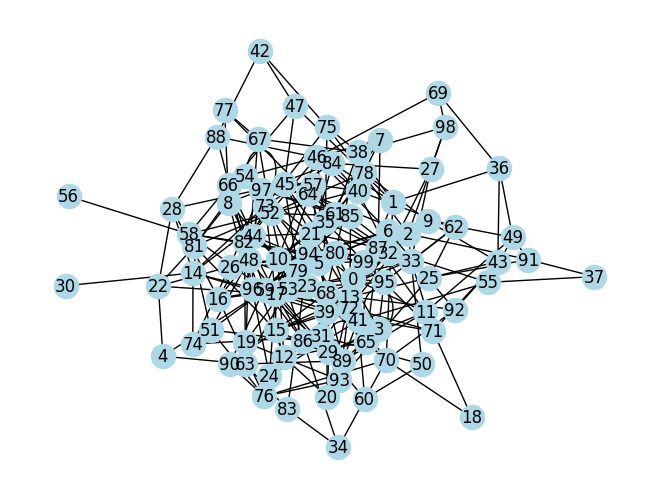

0.0696 MB dla 100


In [11]:
N = 10000
M = 3*N
edges = np.random.randint(0,N, size = (M,2)).tolist()
obiekt  = np.zeros((N,N),dtype = np.uint8)
for i,j in edges:
    obiekt[i,j] = obiekt[j,i] =1 

print(f"{asizeof.asizeof(obiekt)/1e6} MB")

adj = [[] for _ in range(N)]
for i,j in edges:
    adj[i].append(j)
    adj[j].append(i)


indicies, indptr = [],[0]    
for neighbours in adj:
    indicies.extend(neighbours)
    indptr.append(len(indicies))
indicies = np.array(indicies,dtype=np.int32)
indptr = np.array(indptr,dtype=np.int32)


print(f"{asizeof.asizeof(indicies,indptr)/1e6} MB")

Ns= [100]
for N in Ns:
    M = 3*N
    edges = np.random.randint(0,N, size = (M,2)).tolist()
    G  = nx.from_edgelist(edges)
    nx.draw(G,with_labels=True,node_color="lightblue")
    plt.show()  #?
    print(f"{asizeof.asizeof(G)/1e6} MB dla {N}")


In [14]:
from numba import njit

def f(x):
    for _ in range(1000000): x = x*3.9*(1-x)
    return x

g = njit(f)
g(0.2)
%timeit g(0.2)


2.54 ms ± 85 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [21]:
import random
def BA(N, m):
    adj = [[] for _ in range(m + 1)]
    repeated = []
    for i in range(m + 1):
        for j in range(i + 1, m + 1):
            adj[i].append(j)
            adj[j].append(i)
            repeated.extend([i, j])
    # Dodawanie kolejnych węzłów
    for i in range(m + 1, N):
        targets = set()
        while len(targets) < m:
            targets.add(random.choice(repeated))
        adj.append(list(targets))
        for j in targets:
            adj[j].append(i)
            repeated.extend([i, j])
    return adj

def DMS(N,m,gamma):
    adj = [[] for _ in range(m + 1)]
    repeated = []
    for i in range(m + 1):
        for j in range(i + 1, m + 1):
            adj[i].append(j)
            adj[j].append(i)
            repeated.extend([i, j])
    # Dodawanie kolejnych węzłów
    for i in range(m + 1, N):
        targets = set()
        A = m*(gamma -3) 
        while len(targets) < m:
            j = random.choice(repeated)
            k = len(adj[j])
            if np.random.rand() < (k+A)/k:
                targets.add(j)
            # targets.add(random.choice(repeated))
        adj.append(list(targets))
        for j in targets:
            adj[j].append(i)
            repeated.extend([i, j])
    return adj


In [24]:
N = 10000
# siec = BA(N,3)
siec = DMS(N,3,2.1)


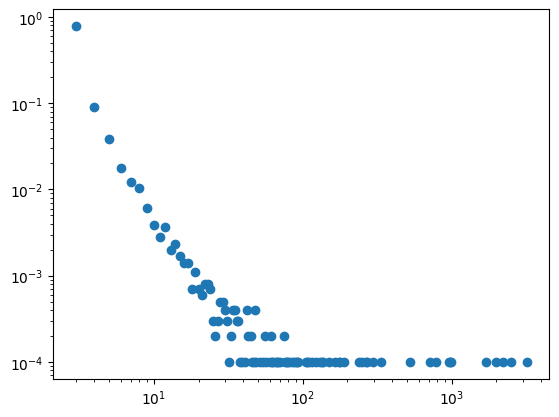

In [25]:
k = []
for wezel in siec:
    k.append(len(wezel))
vals,counts = np.unique(k,return_counts=True)
plt.loglog(vals,counts/N,'o')
plt.show()

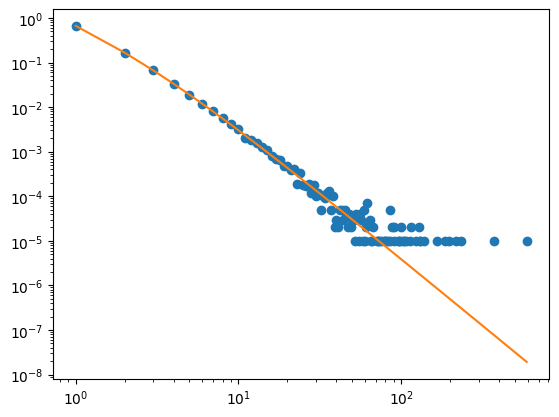

In [17]:
N = 100000
m = 1

siec = nx.barabasi_albert_graph(N,m)
k = np.array([d for _,d in  siec.degree()])
vals,counts = np.unique(k,return_counts = True)


P = (2*m*(m+1))/(vals*(vals+1)*(vals+2))
plt.loglog(vals,counts/N,'o')
plt.loglog(vals,P)

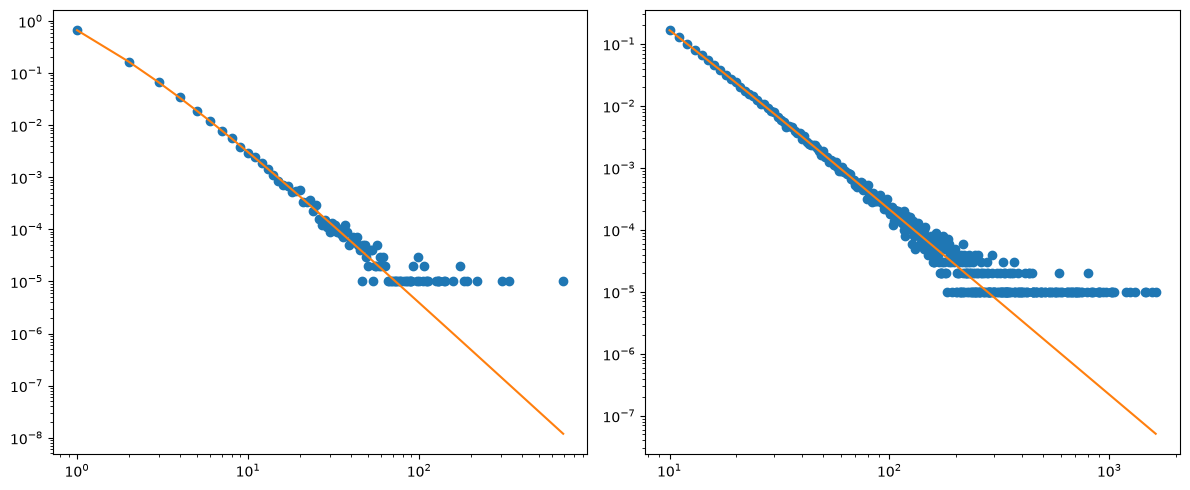

In [23]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

N = 100000
m_values = [1, 10]

# Tworzenie figury z dwoma podwykresami obok siebie
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for i, m in enumerate(m_values):
    siec = nx.barabasi_albert_graph(N, m)
    k = np.array([d for _, d in siec.degree()])
    vals, counts = np.unique(k, return_counts=True)
    
    # Teoretyczny rozkład stopni
    P = (2 * m * (m + 1)) / (vals * (vals + 1) * (vals + 2))
    
    # Wybór odpowiedniej osi dla danego m
    ax = axes[i]
    ax.loglog(vals, counts / N, 'o')
    ax.loglog(vals, P)
    


plt.tight_layout()
plt.show()